# DSA4213 Assignment 1 — Part I: Language Model Comparison (Colab version)

**Attribution:** tokenizer, n-gram LM (add-k smoothing, interpolation) and evaluation adapted from the DSA4213 Lecture 1 notebook; RNN, LSTM and Transformer LMs adapted from the DSA4213 Lecture 3 notebook.

**Before running:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.

**Notebook structure**

* **Cell 0: Colab setup.** Mounts Google Drive so data, checkpoints and results survive Colab disconnects, sets the working directory and checks that a GPU is available.
* **Cell 1: Data.** Reads WikiText-2 from `data/processed/` on Drive if present; otherwise downloads `wikitext-2-raw-v1` from Hugging Face (public, no API token needed).
* **Cell 2: Shared utilities and tokenizer (used by all models).** Cleans WikiText's `@-@`, `@,@`, `@.@` markers, lowercases and tokenizes, wraps each line in `<s> … </s>`, and builds a 30k vocabulary with `<unk>` and `<pad>`.
* **Cell 3: N-gram language model.** Defines the trigram model: counting, smoothing and interpolation across unigram, bigram and trigram orders, plus the evaluation function.
* **Cell 4: Train and evaluate the trigram.** Fits the trigram on the same token stream and 30k vocabulary as the neural models, so perplexities are comparable. Tunes the smoothing hyperparameters on the dev set and reports test cross-entropy, perplexity, model size and speed.
* **Cell 5: Neural models and data loaders.** Defines the vanilla RNN, the LSTM and a decoder-only (GPT-style) Transformer with causal self-attention, all with the same dropout placement. Also defines the data loader, which splits the token stream into fixed-length windows of input and next-token target.
* **Cell 6: Shared training and evaluation loop.** One `train_model()` for RNN, LSTM and Transformer, with shared hyperparameters (`BASE_CFG`), mixed precision (AMP), gradient clipping and early stopping on validation perplexity. Logs per-epoch loss, wall-clock time, parameter count and inference throughput, and saves a checkpoint and history to Drive every epoch.
* **Cell 7: RNN.** Trains and evaluates the vanilla RNN.
* **Cell 8: LSTM.** Trains and evaluates the LSTM.
* **Cell 9: Transformer.** Trains and evaluates the decoder-only Transformer.
* **Cell 10: Results table.** Collects test perplexity, cross-entropy, best validation perplexity, parameters, training time and inference speed for all four models, and saves it to `results/metrics_part1.csv`.
* **Cell 11: Loss curves.** Plots training and validation cross-entropy per epoch for the three neural models and saves it to `results/loss_curves_part1.png`.
* **Cell 12: Text generation.** Generates continuations of the same prompts from each neural model with identical decoding settings (temperature 0.8, top-k 40, fixed seed, 32-token context window) and saves them to `results/generations.md`.

In [1]:
# ==========================================
# CELL 0: SETUP (identical in every notebook)
# ==========================================
import os, sys, subprocess, zipfile, urllib.request
from pathlib import Path
import torch

REPO_URL  = "https://github.com/LeuRNburgJoe11/DSA4213_Assignment.git"
REPO_NAME = "DSA4213_Assignment"
CKPT_URL  = ("https://github.com/LeuRNburgJoe11/DSA4213_Assignment/"
             "releases/download/v1.0/checkpoints.zip")

IN_COLAB = "google.colab" in sys.modules

def _is_repo_root(p: Path) -> bool:
    return (p / "README.md").exists() and (p / "data" / "prepare_data.py").exists()

if IN_COLAB:
    PROJECT_DIR = Path("/content") / REPO_NAME
    if not PROJECT_DIR.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_DIR)], check=True)
else:
    here = Path.cwd().resolve()
    PROJECT_DIR = next((p for p in [here, *here.parents] if _is_repo_root(p)), here)

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
(PROJECT_DIR / "results" / "part2").mkdir(parents=True, exist_ok=True)

def require(path, hint=""):
    """Fail early with a clear message instead of deep inside a later cell."""
    if not (PROJECT_DIR / path).exists():
        raise FileNotFoundError(f"Missing {path}. {hint}")

def ensure_wikitext():
    """Rebuild data/processed/{train,valid,test}.txt if this runtime doesn't have them."""
    if not all((PROJECT_DIR / "data/processed" / f"{s}.txt").exists()
               for s in ("train", "valid", "test")):
        subprocess.run([sys.executable, "data/prepare_data.py"], check=True)

def ensure_rt_prepared():
    """Build data/prepared/rt_*.csv by executing the data-prep notebook in this runtime."""
    if all((PROJECT_DIR / "data/prepared" / f"rt_{s}.csv").exists()
           for s in ("train", "valid", "test")):
        return
    ensure_wikitext()
    require("data/raw/rotten_tomatoes_critic_reviews.csv",
            "Download it from Kaggle (see README > Data access) and upload it to data/raw/.")
    subprocess.run(["jupyter", "nbconvert", "--to", "notebook", "--execute",
                    "Part3_data_prep_RottenTomatoes.ipynb",
                    "--output", "/tmp/part3_prep_executed.ipynb"], check=True)

def ensure_checkpoints():
    """Fetch the trained LSTM checkpoints (Parts I-II) from the GitHub release."""
    have_p1 = (PROJECT_DIR / "results/lstm.pt").exists()
    have_p2 = len(list((PROJECT_DIR / "results/part2").glob("lstm_*.pt"))) >= 12
    if have_p1 and have_p2:
        return
    zpath = PROJECT_DIR / "checkpoints.zip"
    print("Downloading checkpoints from GitHub release ...")
    urllib.request.urlretrieve(CKPT_URL, zpath)
    with zipfile.ZipFile(zpath) as z:
        z.extractall(PROJECT_DIR)  # contains results/lstm.pt and results/part2/lstm_*.pt
    zpath.unlink()

print("Working directory:", Path.cwd())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: No GPU available. In Colab, select: Runtime > Change runtime type > T4 GPU")

Working directory: /content/DSA4213_Assignment
GPU: Tesla T4


In [2]:
# ==========================================
# CELL 1: DATA — use data/processed/ if present, else download WikiText-2
# ==========================================
# DATA_SOURCE: "auto"  -> use existing data/processed/*.txt, otherwise
#              "hf"    -> always (re)download wikitext-2-raw-v1 and overwrite
DATA_SOURCE = "auto"

results_path = Path("results"); results_path.mkdir(exist_ok=True)
data_dir = Path("data/processed"); data_dir.mkdir(parents=True, exist_ok=True)
train_path, valid_path, test_path = (data_dir / f"{t}.txt" for t in ("train", "valid", "test"))

have_local = all(p.exists() for p in (train_path, valid_path, test_path))
if DATA_SOURCE == "hf" or not have_local:
    try:
        from datasets import load_dataset
    except ImportError:
        !pip -q install datasets
        from datasets import load_dataset
    # Public dataset: no Hugging Face token required.
    ds = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")
    for split, path in (("train", train_path), ("validation", valid_path), ("test", test_path)):
        path.write_text("".join(ds[split]["text"]), encoding="utf-8")
    print("Downloaded wikitext-2-raw-v1 from Hugging Face into data/processed/")
else:
    print("Using existing files in data/processed/")

for p in (train_path, valid_path, test_path):
    print(f"{p.name:10s} {p.stat().st_size/1e6:6.2f} MB")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Downloaded wikitext-2-raw-v1 from Hugging Face into data/processed/
train.txt   10.91 MB
valid.txt    1.14 MB
test.txt     1.29 MB


In [3]:
# ==========================================
# CELL 2: SHARED UTILITIES & TOKENIZER (used by ALL models)
# ==========================================
import re, math, json, time, copy, random
from collections import Counter, defaultdict
import numpy as np

START_TOKEN, END_TOKEN = "<s>", "</s>"
PAD_TOKEN, UNK_TOKEN = "<pad>", "<unk>"

TOKEN_PATTERN = re.compile(r"\w+(?:'\w+)?|[^\w\s]")
WIKITEXT_MARKERS = re.compile(r" @([-,.])@ ")   # " @-@ " -> "-", " @,@ " -> ",", " @.@ " -> "."

def clean_wikitext(line):
    """Undo WikiText's @x@ escaping so e.g. '1 @,@ 000' becomes '1,000'.
    Otherwise each marker becomes 3 tokens that suppresses every model's perplexity."""
    return WIKITEXT_MARKERS.sub(r"\1", line)

def tokenize(text):
    normalized = clean_wikitext(text).lower().replace("’", "'")
    return TOKEN_PATTERN.findall(normalized)

def read_tokens(path):
    #One continuous token stream; each non-empty line wrapped in <s> ... </s>.
    tokens = []
    for line in Path(path).read_text(encoding="utf-8").splitlines():
        line_tokens = tokenize(line.strip())
        if line_tokens:
            tokens.extend([START_TOKEN, *line_tokens, END_TOKEN])
    return tokens

def build_vocabulary(tokens, max_vocab_size=30000):
    counts = Counter(tokens)
    most_common = [t for t, _ in counts.most_common(max_vocab_size)]
    vocabulary = [PAD_TOKEN, UNK_TOKEN] + sorted(set(most_common) - {PAD_TOKEN, UNK_TOKEN})
    return {t: i for i, t in enumerate(vocabulary)}, vocabulary

def map_to_vocab(tokens, token_to_id):
    return [t if t in token_to_id else UNK_TOKEN for t in tokens]

def compute_perplexity(avg_cross_entropy_bits):
    return 2 ** avg_cross_entropy_bits

MAX_VOCAB_SIZE = 30000  #upper limit for ALL models
train_tokens = read_tokens(train_path)
valid_tokens = read_tokens(valid_path)
test_tokens  = read_tokens(test_path)
token_to_id, vocabulary = build_vocabulary(train_tokens, MAX_VOCAB_SIZE)

n_unk = sum(t not in token_to_id for t in train_tokens)
print(f"Train tokens: {len(train_tokens):,} | valid tokens: {len(valid_tokens):,} | test tokens: {len(test_tokens):,}")
print(f"Unique train types: {len(set(train_tokens)):,} | vocab (incl. pad/unk tokens): {len(vocabulary):,}")
print(f"Train tokens mapped to <unk>: {n_unk:,} ({n_unk/len(train_tokens):.2%})")
print("Remaining '@' tokens in train:", sum(t == "@" for t in train_tokens))

Train tokens: 2,124,061 | valid tokens: 221,501 | test tokens: 249,435
Unique train types: 65,992 | vocab (incl. pad/unk tokens): 30,002
Train tokens mapped to <unk>: 45,140 (2.13%)
Remaining '@' tokens in train: 8


In [4]:
# ==========================================
# CELL 3: N-GRAM LANGUAGE MODEL (same token stream + vocab as neural models)
# ==========================================
class CountLanguageModel:
    """Interpolated add-k n-gram LM (where n = 3) over a continuous token stream.
    Predicting every subsequent token after the first."""
    def __init__(self, max_order=3, k=1.0):
        self.max_order = max_order
        self.k = k  # Default add-k parameter (Smoothing if k=1.0)
        self.next_counts = {o: defaultdict(Counter) for o in range(1, max_order + 1)}
        self.history_counts = {o: Counter() for o in range(1, max_order + 1)}
        self.vocab_size = 0

    def fit(self, tokens, vocab_size):
        self.vocab_size = vocab_size
        for order in range(1, self.max_order + 1):
            nc, hc = self.next_counts[order], self.history_counts[order]
            for pos in range(order - 1, len(tokens)):
                history = tuple(tokens[pos - order + 1: pos])
                nc[history][tokens[pos]] += 1
                hc[history] += 1
        return self

    def probability(self, history, word, order, add_k=None):
        """Calculates add-k smoothed probability for a single n-gram order.
        Formula used from Lecture 1: (Count(word, history) + k) / (Count(history) + k * |V|)"""
        if add_k is None:
            add_k = self.k

        h = tuple(history[len(history) - (order - 1):]) if order > 1 else ()

        # Retrieve count of (word, history)
        count_hw = self.next_counts[order][h][word] if h in self.next_counts[order] else 0
        # Retrieve total count of history context
        count_h = self.history_counts[order][h] if h in self.history_counts[order] else 0

        numerator = count_hw + add_k
        denominator = count_h + (add_k * self.vocab_size)

        # Edge case: Fallback to uniform distribution if denominator is 0 (e.g. k=0 and unseen history)
        if denominator == 0:
            return 1.0 / self.vocab_size if self.vocab_size > 0 else 0.0
        return numerator / denominator

    def interpolated_probability(self, history, word, weights, add_k=None):
        if add_k is None:
            add_k = self.k
        return sum(w * self.probability(history, word, o, add_k) for o, w in weights.items())

    def evaluate_ngram_model(model, tokens, weights, add_k=None):
      if add_k is None:
        add_k = model.k
      n = model.max_order
      log_prob_sum, count = 0.0, 0
      for pos in range(1, len(tokens)):
        history = tokens[max(0, pos - n + 1): pos]
        p = model.interpolated_probability(history, tokens[pos], weights, add_k)
        log_prob_sum += math.log2(max(p, 1e-12))
        count += 1

      ce = -log_prob_sum / count
      return ce, 2 ** ce

In [5]:
# ==========================================
# CELL 4: TRAIN & EVALUATE N-GRAM MODEL (tune add_k AND interpolation weights on dev)
# ==========================================
import itertools

ng_train = map_to_vocab(train_tokens, token_to_id)
ng_valid = map_to_vocab(valid_tokens, token_to_id)
ng_test  = map_to_vocab(test_tokens,  token_to_id)
ngram_vocab_size = len(vocabulary) - 1  # exclude <pad>, which is never predicted

max_order = 3
t0 = time.perf_counter()
ngram_model = CountLanguageModel(max_order).fit(ng_train, ngram_vocab_size)
ngram_fit_time = time.perf_counter() - t0

def per_order_probs(model, tokens, add_k):
    """P[i, o-1] = add-k probability of target i under order o (same targets as evaluate_ngram_model)."""
    n = model.max_order
    P = np.empty((len(tokens) - 1, n))
    for pos in range(1, len(tokens)):
        history = tokens[max(0, pos - n + 1): pos]
        for o in range(1, n + 1):
            P[pos - 1, o - 1] = model.probability(history, tokens[pos], o, add_k)
    return P

def ce_bits(P, lambdas):
    return -np.mean(np.log2(np.maximum(P @ np.asarray(lambdas), 1e-12)))

# lambda grid over the simplex in steps of 0.05 (λ1 + λ2 + λ3 = 1, each > 0)
step = 0.05
LAMBDA_GRID = [(a, b, round(1 - a - b, 2))
               for a, b in itertools.product(np.arange(step, 1, step).round(2), repeat=2)
               if 1 - a - b > 1e-9]
K_GRID = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2]

print("--- Tuning add_k and (λ1, λ2, λ3) on dev set ---")
tuning_log = []
best_k, best_lambdas, best_dev_pp = None, None, float("inf")
for k in K_GRID:
    P = per_order_probs(ngram_model, ng_valid, k)
    k_best = min(LAMBDA_GRID, key=lambda lam: ce_bits(P, lam))
    pp = 2 ** ce_bits(P, k_best)
    uniform_pp = 2 ** ce_bits(P, (1/3, 1/3, 1/3))
    tuning_log.append({"add_k": k, "lambdas": k_best, "dev_ppl": pp, "dev_ppl_uniform": uniform_pp})
    print(f"add_k = {k:<7g} | best λ = {k_best} | dev PPL {pp:7.2f} (uniform λ: {uniform_pp:7.2f})")
    if pp < best_dev_pp:
        best_k, best_lambdas, best_dev_pp = k, k_best, pp

if best_k in (K_GRID[0], K_GRID[-1]):
    print("WARNING: best add_k is at the edge of K_GRID — extend the grid.")

weights = {o: best_lambdas[o - 1] for o in range(1, max_order + 1)}  # global, also used in Cell 12

t0 = time.perf_counter()
test_ce, test_pp = ngram_model.evaluate_ngram_model(ng_test, weights, best_k)
ngram_eval_time = time.perf_counter() - t0

n_ngram_entries = sum(sum(len(c) for c in ngram_model.next_counts[o].values()) for o in range(1, max_order + 1))
ngram_result = {
    "model": "trigram", "test_ce_bits": test_ce, "test_ppl": test_pp, "best_valid_ppl": best_dev_pp,
    "params": n_ngram_entries, "train_time_s": ngram_fit_time,
    "infer_tokens_per_s": (len(ng_test) - 1) / ngram_eval_time, "device": "cpu",
    "add_k": best_k, "lambdas": list(best_lambdas),
}
(results_path / "ngram_tuning.json").write_text(json.dumps(tuning_log, indent=1))
(results_path / "result_trigram.json").write_text(json.dumps(ngram_result, indent=1))
print(f"\nBest add_k: {best_k} | λ = {best_lambdas} | test CE: {test_ce:.4f} bits | test PPL: {test_pp:.2f}")
print(f"Stored n-gram entries: {n_ngram_entries:,} | fit time: {ngram_fit_time:.1f}s")

--- Tuning add_k and (λ1, λ2, λ3) on dev set ---
add_k = 1e-05   | best λ = (np.float64(0.3), np.float64(0.5), np.float64(0.2)) | dev PPL  260.19 (uniform λ:  268.24)
add_k = 3e-05   | best λ = (np.float64(0.25), np.float64(0.55), np.float64(0.2)) | dev PPL  259.73 (uniform λ:  268.05)
add_k = 0.0001  | best λ = (np.float64(0.25), np.float64(0.55), np.float64(0.2)) | dev PPL  261.14 (uniform λ:  270.96)
add_k = 0.0003  | best λ = (np.float64(0.25), np.float64(0.55), np.float64(0.2)) | dev PPL  266.80 (uniform λ:  279.62)
add_k = 0.001   | best λ = (np.float64(0.25), np.float64(0.6), np.float64(0.15)) | dev PPL  280.90 (uniform λ:  299.67)
add_k = 0.003   | best λ = (np.float64(0.25), np.float64(0.65), np.float64(0.1)) | dev PPL  304.41 (uniform λ:  331.62)
add_k = 0.01    | best λ = (np.float64(0.25), np.float64(0.7), np.float64(0.05)) | dev PPL  347.15 (uniform λ:  386.95)

Best add_k: 3e-05 | λ = (np.float64(0.25), np.float64(0.55), np.float64(0.2)) | test CE: 7.9478 bits | test PPL:

In [ ]:
# ==========================================
# CELL 5: NEURAL MODELS for RNN, LSTM, TRANSFORMER & DATA LOADERS
# ==========================================
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

class VanillaRNNLM(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, dropout=0.0, tie_weights=True):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.proj = nn.Linear(hidden_dim, embed_dim)          # hidden -> embed so the output can be tied
        self.fc = nn.Linear(embed_dim, vocab_size)
        if tie_weights:
            self.fc.weight = self.embedding.weight

    def forward(self, x, hidden=None):
        out, hidden = self.rnn(self.drop(self.embedding(x)), hidden)
        return self.fc(self.proj(self.drop(out))), hidden

class LSTMLanguageModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_layers=1, dropout=0.0, tie_weights=True):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.proj = nn.Linear(hidden_dim, embed_dim)
        self.fc = nn.Linear(embed_dim, vocab_size)
        if tie_weights:
            self.fc.weight = self.embedding.weight

    def forward(self, x, hidden=None):
        out, hidden = self.lstm(self.drop(self.embedding(x)), hidden)
        return self.fc(self.proj(self.drop(out))), hidden

class PositionalEncoding(nn.Module):
    def __init__(self, embed_dim, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, embed_dim)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, embed_dim, 2).float() * (-math.log(10000.0) / embed_dim))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class DecoderOnlyTransformerLM(nn.Module):
    """GPT-style LM: a single causally-masked self-attention stack."""
    def __init__(self, vocab_size, embed_dim, nhead, hidden_dim, num_layers, dropout=0.1, tie_weights=True):
        super().__init__()
        self.embed_dim = embed_dim
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.pos_encoder = PositionalEncoding(embed_dim)
        self.drop = nn.Dropout(dropout)
        layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=nhead,
                                           dim_feedforward=hidden_dim, dropout=dropout)
        self.blocks = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.fc = nn.Linear(embed_dim, vocab_size)
        self.fc.weight = self.embedding.weight   # weight tying: helps a lot on small data
        if tie_weights:
            self.fc.weight = self.embedding.weight

    def forward(self, x, hidden=None):
        T = x.size(1)
        mask = nn.Transformer.generate_square_subsequent_mask(T, device=x.device)
        h = self.drop(self.pos_encoder(self.embedding(x) * math.sqrt(self.embed_dim)))

        h = self.blocks(h.transpose(0, 1), mask=mask).transpose(0, 1)   # seq-first for old PyTorch
        return self.fc(h), None


def make_data_loader(tokens, token_to_id, sequence_length, batch_size, shuffle):
    unk = token_to_id[UNK_TOKEN]
    ids = torch.tensor([token_to_id.get(t, unk) for t in tokens], dtype=torch.long)
    n = (len(ids) - 1) // sequence_length
    inputs  = ids[: n * sequence_length].view(n, sequence_length)
    targets = ids[1: n * sequence_length + 1].view(n, sequence_length)
    return DataLoader(TensorDataset(inputs, targets), batch_size=batch_size, shuffle=shuffle,
                      pin_memory=torch.cuda.is_available())

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"      # mixed precision: ~2x faster on a T4
print("device:", device, "| AMP:", USE_AMP)

device: cuda | AMP: True


In [ ]:
# ==========================================
# CELL 6: ONE SHARED TRAIN & EVALUATE LOOP (timing + loss history)
# ==========================================
def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

@torch.no_grad()
def evaluate_neural_model(model, loader, criterion):
    """Returns (cross-entropy bits/token, perplexity, tokens/sec)."""
    model.eval()
    total_loss, total_tokens = 0.0, 0
    sync(); t0 = time.perf_counter()
    for inputs, targets in loader:
        inputs, targets = inputs.to(device, non_blocking=True), targets.to(device, non_blocking=True)
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            logits, _ = model(inputs)
        loss = criterion(logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1))
        total_loss += loss.item()
        total_tokens += (targets != criterion.ignore_index).sum().item()
    sync(); elapsed = time.perf_counter() - t0
    bits = total_loss / total_tokens / math.log(2)
    return bits, compute_perplexity(bits), total_tokens / elapsed

def train_model(name, model, cfg, train_loader, valid_loader, criterion):
    """Shared by all neural LMs so the comparison is fair. Saves a checkpoint and
    a JSON history every epoch (to Drive), so a Colab disconnect loses little."""
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["learning_rate"])
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    history = {"epoch": [], "train_bits": [], "valid_bits": [], "valid_ppl": [], "epoch_time_s": []}
    best_valid_ppl, best_state, bad_epochs = float("inf"), None, 0

    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        total_loss, total_tokens = 0.0, 0
        sync(); t0 = time.perf_counter()
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device, non_blocking=True), targets.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
                logits, _ = model(inputs)
            loss = criterion(logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1))
            n_tok = targets.numel()
            scaler.scale(loss / n_tok).backward()        # mean loss for stable gradients
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer); scaler.update()
            total_loss += loss.item(); total_tokens += n_tok
        sync(); epoch_time = time.perf_counter() - t0

        train_bits = total_loss / total_tokens / math.log(2)
        valid_bits, valid_ppl, _ = evaluate_neural_model(model, valid_loader, criterion)
        for k, v in zip(history, (epoch, train_bits, valid_bits, valid_ppl, epoch_time)):
            history[k].append(v)
        print(f"[{name}] epoch {epoch:02d} | train CE {train_bits:.3f} bits | valid CE {valid_bits:.3f} bits "
              f"| valid PPL {valid_ppl:8.2f} | {epoch_time:6.1f}s")

        if valid_ppl < best_valid_ppl:
            best_valid_ppl, bad_epochs = valid_ppl, 0
            best_state = copy.deepcopy(model.state_dict())
            torch.save({"model_state_dict": best_state, "token_to_id": token_to_id,
                        "vocabulary": vocabulary, "config": cfg}, results_path / f"{name}.pt")
        else:
            bad_epochs += 1
        (results_path / f"history_{name}.json").write_text(json.dumps(history, indent=1))
        if bad_epochs >= cfg["patience"]:
            print(f"[{name}] early stopping after epoch {epoch}")
            break

    model.load_state_dict(best_state)
    return best_valid_ppl, history

def run_experiment(name, model, cfg):
    set_seed(cfg["seed"])
    train_loader = make_data_loader(train_tokens, token_to_id, cfg["sequence_length"], cfg["batch_size"], True)
    valid_loader = make_data_loader(valid_tokens, token_to_id, cfg["sequence_length"], cfg["batch_size"], False)
    test_loader  = make_data_loader(test_tokens,  token_to_id, cfg["sequence_length"], cfg["batch_size"], False)
    criterion = nn.CrossEntropyLoss(ignore_index=token_to_id[PAD_TOKEN], reduction="sum")

    print(f"\n=== {name}: {count_params(model):,} parameters ===")
    best_valid_ppl, history = train_model(name, model, cfg, train_loader, valid_loader, criterion)
    test_bits, test_ppl, tok_per_s = evaluate_neural_model(model, test_loader, criterion)
    result = {
        "model": name, "test_ce_bits": test_bits, "test_ppl": test_ppl, "best_valid_ppl": best_valid_ppl,
        "params": count_params(model), "train_time_s": sum(history["epoch_time_s"]),
        "epochs_run": len(history["epoch"]), "infer_tokens_per_s": tok_per_s,
        "device": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
    }
    print(f"[{name}] TEST CE {test_bits:.4f} bits/token | TEST PPL {test_ppl:.2f} | "
          f"{tok_per_s:,.0f} tokens/s inference")
    (results_path / f"result_{name}.json").write_text(json.dumps(result, indent=1))
    return result

# Shared hyperparameters — identical for all three neural models (fair comparison)
BASE_CFG = dict(epochs=20, batch_size=64, sequence_length=32, embed_dim=100, hidden_dim=256,
                learning_rate=1e-3, dropout=0.3, patience=2, seed=42)
all_results = [ngram_result]

In [8]:
# ==========================================
# CELL 7: RNN
# ==========================================
rnn_cfg = dict(BASE_CFG)
set_seed(rnn_cfg["seed"])
rnn_model  = VanillaRNNLM(len(vocabulary), rnn_cfg["embed_dim"], rnn_cfg["hidden_dim"],
                          dropout=rnn_cfg["dropout"])
all_results.append(run_experiment("rnn", rnn_model, rnn_cfg))


=== rnn: 3,147,550 parameters ===
[rnn] epoch 01 | train CE 10.087 bits | valid CE 9.004 bits | valid PPL   513.26 |   22.1s
[rnn] epoch 02 | train CE 9.229 bits | valid CE 8.760 bits | valid PPL   433.39 |   20.0s
[rnn] epoch 03 | train CE 9.010 bits | valid CE 8.561 bits | valid PPL   377.63 |   20.0s
[rnn] epoch 04 | train CE 8.852 bits | valid CE 8.426 bits | valid PPL   343.97 |   20.2s
[rnn] epoch 05 | train CE 8.730 bits | valid CE 8.344 bits | valid PPL   324.90 |   20.2s
[rnn] epoch 06 | train CE 8.633 bits | valid CE 8.274 bits | valid PPL   309.46 |   20.1s
[rnn] epoch 07 | train CE 8.549 bits | valid CE 8.203 bits | valid PPL   294.68 |   20.1s
[rnn] epoch 08 | train CE 8.476 bits | valid CE 8.158 bits | valid PPL   285.72 |   20.1s
[rnn] epoch 09 | train CE 8.409 bits | valid CE 8.114 bits | valid PPL   276.98 |   20.1s
[rnn] epoch 10 | train CE 8.345 bits | valid CE 8.060 bits | valid PPL   266.96 |   20.1s
[rnn] epoch 11 | train CE 8.287 bits | valid CE 8.021 bits | val

In [9]:
# ==========================================
# CELL 8: LSTM
# ==========================================
lstm_cfg = dict(BASE_CFG)
set_seed(lstm_cfg["seed"])
lstm_model = LSTMLanguageModel(len(vocabulary), lstm_cfg["embed_dim"], lstm_cfg["hidden_dim"],
                               dropout=lstm_cfg["dropout"])
all_results.append(run_experiment("lstm", lstm_model, lstm_cfg))


=== lstm: 3,422,494 parameters ===
[lstm] epoch 01 | train CE 9.806 bits | valid CE 8.754 bits | valid PPL   431.80 |   21.4s
[lstm] epoch 02 | train CE 8.955 bits | valid CE 8.445 bits | valid PPL   348.61 |   21.4s
[lstm] epoch 03 | train CE 8.692 bits | valid CE 8.238 bits | valid PPL   301.91 |   21.3s
[lstm] epoch 04 | train CE 8.503 bits | valid CE 8.081 bits | valid PPL   270.83 |   21.4s
[lstm] epoch 05 | train CE 8.361 bits | valid CE 7.990 bits | valid PPL   254.18 |   21.4s
[lstm] epoch 06 | train CE 8.247 bits | valid CE 7.895 bits | valid PPL   238.09 |   21.3s
[lstm] epoch 07 | train CE 8.149 bits | valid CE 7.814 bits | valid PPL   224.97 |   21.3s
[lstm] epoch 08 | train CE 8.062 bits | valid CE 7.755 bits | valid PPL   215.96 |   21.4s
[lstm] epoch 09 | train CE 7.984 bits | valid CE 7.696 bits | valid PPL   207.33 |   21.4s
[lstm] epoch 10 | train CE 7.909 bits | valid CE 7.638 bits | valid PPL   199.18 |   21.4s
[lstm] epoch 11 | train CE 7.842 bits | valid CE 7.588

In [10]:
# ==========================================
# CELL 9: TRANSFORMER
# ==========================================
tx_cfg = dict(BASE_CFG, nhead=4, num_layers=2)
set_seed(tx_cfg["seed"])
tx_model   = DecoderOnlyTransformerLM(len(vocabulary), tx_cfg["embed_dim"], tx_cfg["nhead"],
                                      tx_cfg["hidden_dim"], tx_cfg["num_layers"],
                                      dropout=tx_cfg["dropout"])
all_results.append(run_experiment("transformer", tx_model, tx_cfg))

/tmp/ipykernel_591/3841662712.py:61: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.blocks = nn.TransformerEncoder(layer, num_layers=num_layers)



=== transformer: 3,214,914 parameters ===
[transformer] epoch 01 | train CE 13.608 bits | valid CE 9.354 bits | valid PPL   654.39 |   25.0s
[transformer] epoch 02 | train CE 9.605 bits | valid CE 9.107 bits | valid PPL   551.48 |   24.7s
[transformer] epoch 03 | train CE 9.409 bits | valid CE 8.938 bits | valid PPL   490.32 |   24.7s
[transformer] epoch 04 | train CE 9.269 bits | valid CE 8.811 bits | valid PPL   449.13 |   24.8s
[transformer] epoch 05 | train CE 9.152 bits | valid CE 8.695 bits | valid PPL   414.43 |   24.8s
[transformer] epoch 06 | train CE 9.046 bits | valid CE 8.612 bits | valid PPL   391.15 |   24.7s
[transformer] epoch 07 | train CE 8.953 bits | valid CE 8.525 bits | valid PPL   368.42 |   24.8s
[transformer] epoch 08 | train CE 8.873 bits | valid CE 8.460 bits | valid PPL   352.24 |   24.8s
[transformer] epoch 09 | train CE 8.803 bits | valid CE 8.405 bits | valid PPL   338.89 |   24.7s
[transformer] epoch 10 | train CE 8.745 bits | valid CE 8.378 bits | valid

In [11]:
# ==========================================
# CELL 10: RESULTS TABLE
# ==========================================
import pandas as pd
df = pd.DataFrame(all_results)[["model", "test_ppl", "test_ce_bits", "best_valid_ppl", "params",
                                "train_time_s", "infer_tokens_per_s", "device"]]
df.to_csv(results_path / "metrics_part1.csv", index=False)
df.round(2)

,model,test_ppl,test_ce_bits,best_valid_ppl,params,train_time_s,infer_tokens_per_s,device
0,trigram,246.90,7.95,259.73,2009444,8.65,188860.11,cpu
1,rnn,203.74,7.67,220.19,3147550,404.14,240492.36,Tesla T4
2,lstm,150.32,7.23,160.68,3422494,427.07,229937.99,Tesla T4
3,transformer,259.41,8.02,275.41,3214914,495.01,178460.78,Tesla T4


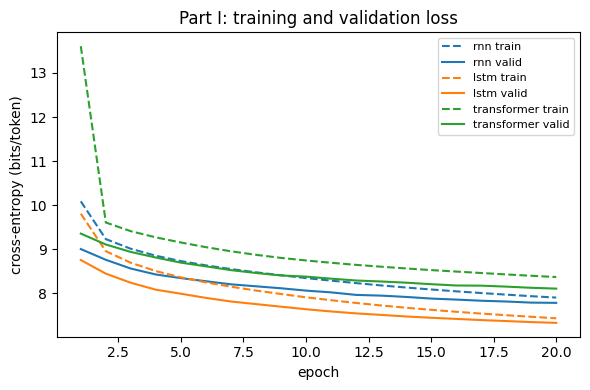

In [12]:
# ==========================================
# CELL 11: LOSS CURVES (one figure for all 4 models)
# ==========================================
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 4))
colors = {"rnn": "tab:blue", "lstm": "tab:orange", "transformer": "tab:green"}
for name, c in colors.items():
    h = json.loads((results_path / f"history_{name}.json").read_text())
    ax.plot(h["epoch"], h["train_bits"], "--", color=c, label=f"{name} train")
    ax.plot(h["epoch"], h["valid_bits"], "-",  color=c, label=f"{name} valid")
ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy (bits/token)")
ax.set_title("Part I: training and validation loss"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(results_path / "loss_curves_part1.png", dpi=200)
plt.show()

In [13]:
# ==========================================
# CELL 12: GENERATION WITH MATCHED DECODING (-> results/generations.md)
# ==========================================
PROMPTS = ["the history of this city", "in 1995 , the band", "the species was found",
           "during the war", "the film was released"]
DECODE = dict(max_new_tokens=30, temperature=0.8, top_k=40, seed=123)

def ngram_next_distribution(model, history, weights, add_k):
    """Full next-token distribution over the vocabulary (same formula as probability())."""
    V = model.vocab_size
    probs = np.zeros(len(vocabulary))
    for order, lam in weights.items():
        h = tuple(history[len(history) - (order - 1):]) if order > 1 else ()
        counter = model.next_counts[order].get(h)
        c_h = model.history_counts[order].get(h, 0)
        counts = np.zeros(len(vocabulary))
        if counter:
            idx = [token_to_id[w] for w in counter]
            counts[idx] = list(counter.values())
        probs += lam * (counts + add_k) / (c_h + add_k * V)
    probs[token_to_id[PAD_TOKEN]] = 0.0
    return probs / probs.sum()

@torch.no_grad()
def generate_ngram(model, prompt, max_new_tokens, temperature, top_k, seed):
    g = torch.Generator(device=device).manual_seed(seed)
    toks = [START_TOKEN] + map_to_vocab(tokenize(prompt), token_to_id)
    for _ in range(max_new_tokens):
        p = ngram_next_distribution(model, toks, weights, best_k)
        logits = torch.tensor(np.log(np.maximum(p, 1e-12)), dtype=torch.float32, device=device)
        logits = logits / temperature
        topv, topi = torch.topk(logits, top_k)
        nxt = topi[torch.multinomial(torch.softmax(topv, -1), 1, generator=g)].item()
        if vocabulary[nxt] == END_TOKEN:
            break
        toks.append(vocabulary[nxt])
    return " ".join(toks[1:])

@torch.no_grad()
def generate(model, prompt, max_new_tokens, temperature, top_k, seed, context_len=32):
    model.eval()
    g = torch.Generator(device=device).manual_seed(seed)
    unk = token_to_id[UNK_TOKEN]
    ids = [token_to_id[START_TOKEN]] + [token_to_id.get(t, unk) for t in tokenize(prompt)]
    for _ in range(max_new_tokens):
        x = torch.tensor([ids[-context_len:]], device=device)
        logits, _ = model(x)
        logits = logits[0, -1].float() / temperature
        logits[token_to_id[PAD_TOKEN]] = -float("inf")
        topv, topi = torch.topk(logits, top_k)
        nxt = topi[torch.multinomial(torch.softmax(topv, -1), 1, generator=g)].item()
        if vocabulary[nxt] == END_TOKEN:
            break
        ids.append(nxt)
    return " ".join(vocabulary[i] for i in ids[1:])

GENERATORS = [
    ("Trigram",     lambda p: generate_ngram(ngram_model, p, **DECODE)),
    ("RNN",         lambda p: generate(rnn_model,  p, **DECODE)),
    ("LSTM",        lambda p: generate(lstm_model, p, **DECODE)),
    ("Transformer", lambda p: generate(tx_model,   p, **DECODE)),
]

lines = [f"# Generated samples (temperature={DECODE['temperature']}, top-k={DECODE['top_k']}, "
         f"max {DECODE['max_new_tokens']} tokens, seed={DECODE['seed']})\n"]
for prompt in PROMPTS:
    lines.append(f"## Prompt: `{prompt}`\n")
    for name, gen in GENERATORS:
        text = gen(prompt)
        lines.append(f"- **{name}:** {text}")
        print(f"{name:12s}| {text}")
    lines.append(""); print()
(results_path / "generations.md").write_text("\n".join(lines), encoding="utf-8")
print("Saved results/generations.md")

Trigram     | the history of this city , and two new zealand and a large <unk> and its in . during the
RNN         | the history of this city is a significant study of the island <unk> and <unk> ' s and form of the roman church . <unk> ) ' s <unk> <unk> , in <unk> , which
LSTM        | the history of this city is a popular of the two and one of the four ships to it .
Transformer | the history of this city , which had been the british war on the united states . " one of the early 20th century . with the latter "

Trigram     | in 1995 , the band , in the early 20th century . <unk> . in to the of ( stuff , but it was " [ lennon intended to be used a novel , "
RNN         | in 1995 , the band ' s episode became the album in <unk> " , she was also held to the " , " the guitar hero to <unk> . " "
LSTM        | in 1995 , the band was released as the best single in the album ' s sixth series <unk> .
Transformer | in 1995 , the band was named the new zealand . the city ' s work , 000 inches ( 